# Susceptibilidades del átomo de cesio en reposo

Este cuaderno evalúa numéricamente las susceptibilidades del Capítulo 2, sin promedio Doppler:

* Lineal, ec. (2.49): $\chi^{(1)}(\omega_3) = \dfrac{N|\mu_{ba}|^2}{\varepsilon_0\hbar\,(\Delta_3 - i\gamma_{ba})}$
* No lineal, ec. (2.54): $\chi^{(3)} = \dfrac{N|\mu_{ba}|^2|\mu_{cb}|^2}{\varepsilon_0\hbar^3\,(\Delta_1 - i\gamma_{ba})(\Delta_2 - i\gamma_{ca})(\Delta_3 - i\gamma_{ba})}$

Convenciones: todo en SI. Las frecuencias angulares y desintonías están en rad/s; las gráficas muestran $\Delta/2\pi$ en MHz.
Niveles: $|a\rangle = 6S_{1/2}$, $|b\rangle = 6P_{3/2}$, $|c\rangle = 8S_{1/2}$.

## 1. Constantes

In [2]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.special import wofz

from constants import cte, c, hbar, kB, eps0, g_ba, g_ca, w_ba, w_ca, w_cb, lmd1, lmd2, lmd3, k1, k2, k3, u

# Se conserva para el Nivel 1 (promedio Doppler); no se usa aquí
Z = lambda z: 1j*np.sqrt(np.pi)*wofz(z)

print(f"lambda1 = {lmd1*1e9:.4f} nm   lambda2 = {lmd2*1e9:.4f} nm   lambda3 = {lmd3*1e9:.4f} nm")
print(f"gamma_ba/2pi = {g_ba/2/np.pi/1e6:.3f} MHz   gamma_ca/2pi = {g_ca/2/np.pi/1e6:.3f} MHz")

lambda1 = 822.4648 nm   lambda2 = 794.6067 nm   lambda3 = 852.3473 nm
gamma_ba/2pi = 2.611 MHz   gamma_ca/2pi = 0.765 MHz


## 2. Parámetros por investigar

Estos tres valores quedan en 1 provisionalmente. Solo cambian la escala de $\chi^{(1)}$ y $\chi^{(3)}$, porque multiplican toda la expresión; no cambian la forma de las curvas en función de las desintonías. Por eso todas las gráficas de este cuaderno están normalizadas y son correctas aunque estos valores sigan siendo 1.

In [3]:
N     = 1.0   # densidad atómica [m^-3]       -> presión de vapor del Cs a la temperatura T
mu_ba = 1.0   # |mu_ba| (6S1/2 <-> 6P3/2) [C*m]
mu_cb = 1.0   # |mu_cb| (6P3/2 <-> 8S1/2) [C*m]

pref1 = N*mu_ba**2/(eps0*hbar)                 # prefactor de (2.49)
pref3 = N*mu_ba**2*mu_cb**2/(eps0*hbar**3)     # prefactor de (2.54)

## 3. De las perillas del laboratorio a las desintonías de la monografía

En el laboratorio se controlan dos frecuencias: la del láser de 822 nm ($\omega_1$) y la del de 794 nm ($\omega_2$). Se parametrizan con:

* $\Delta_2 = \omega_{ca} - 2\omega_1$: desintonía de dos fotones, ec. (2.6).
* $\delta_2 = \omega_{cb} - \omega_2$: desintonía del láser de 794 nm respecto a $8S_{1/2}\to 6P_{3/2}$.

Invirtiendo estas definiciones se obtienen las frecuencias de los láseres. Con la conservación de la energía (2.5), $\omega_3 = 2\omega_1 - \omega_2$ queda fijada, y de ahí salen las otras dos desintonías:

* $\Delta_1 = \omega_{ba} - \omega_1$
* $\Delta_3 = \omega_{ba} - \omega_3 = \Delta_2 - \delta_2$


In [4]:
def frecuencias_laser(D2, d2):
    # Frecuencias angulares de los tres campos a partir de las dos perillas
    w1 = (w_ca - D2)/2
    w2 = w_cb - d2
    w3 = 2*w1 - w2            # conservación de la energía (2.5)
    return w1, w2, w3

def desintonias(D2, d2):
    # Devuelve (Delta1, Delta3) según (2.6)
    w1, w2, w3 = frecuencias_laser(D2, d2)
    D1 = w_ba - w1
    D3 = D2 - d2
    return D1, D3

## 4. Comprobaciones antes de calcular nada

1. **Ajuste de fase en vacío:** $2k_1 - k_2 - k_3$ debe ser cero, porque $2\omega_1 = \omega_2 + \omega_3$ y los tres haces son copropagantes.
2. **Identidad $\Delta_3 = \Delta_2 - \delta_2$:** se compara con el cálculo directo $\omega_{ba} - \omega_3$ para desintonías al azar.
3. **Tamaño de $\Delta_1$:** la monografía afirma (Sec. 2.6.2) que $(\Delta_1 - i\gamma_{ba})$ es grande, casi real y casi constante. Aquí se verifica numéricamente.

In [5]:
# 1. Ajuste de fase en vacío
dk = 2*k1 - k2 - k3
print(f"1) 2k1 - k2 - k3 = {dk:.2e} rad/m   (relativo a k3: {dk/k3:.1e})")

# 2. Identidad Delta3 = Delta2 - delta2
rng = np.random.default_rng(0)
D2s = 2*np.pi*rng.uniform(-100e6, 100e6, 5)
d2s = 2*np.pi*rng.uniform(-100e6, 100e6, 5)
w3s = frecuencias_laser(D2s, d2s)[2]
dif = (w_ba - w3s) - (D2s - d2s)
print(f"2) max |(w_ba - w3) - (D2 - d2)| = {np.max(np.abs(dif)):.1e} rad/s "
      f"(frente a desintonías ~1e8 rad/s: solo redondeo numérico)")

# 3. Delta1
D1_0, _ = desintonias(0.0, 0.0)
D1_20, _ = desintonias(2*np.pi*20e6, 0.0)
print(f"3) Delta1/2pi = {D1_0/2/np.pi/1e12:.3f} THz  (negativo: el 822 está al azul de la D2)")
print(f"   |Delta1|/gamma_ba = {abs(D1_0)/g_ba:.1e}  -> la parte imaginaria es despreciable")
print(f"   cambio relativo de Delta1 al mover Delta2/2pi en 20 MHz: {abs(D1_20-D1_0)/abs(D1_0):.1e}")

1) 2k1 - k2 - k3 = -9.31e-10 rad/m   (relativo a k3: -1.3e-16)
2) max |(w_ba - w3) - (D2 - d2)| = 5.8e-01 rad/s (frente a desintonías ~1e8 rad/s: solo redondeo numérico)
3) Delta1/2pi = -12.779 THz  (negativo: el 822 está al azul de la D2)
   |Delta1|/gamma_ba = 4.9e+06  -> la parte imaginaria es despreciable
   cambio relativo de Delta1 al mover Delta2/2pi en 20 MHz: 7.8e-07


## 5. Las susceptibilidades

* Lineal, ec. (2.49): $\chi^{(1)}(\omega_3) = \dfrac{N|\mu_{ba}|^2}{\varepsilon_0\hbar\,(\Delta_3 - i\gamma_{ba})}$
* No lineal, ec. (2.54): $\chi^{(3)} = \dfrac{N|\mu_{ba}|^2|\mu_{cb}|^2}{\varepsilon_0\hbar^3\,(\Delta_1 - i\gamma_{ba})(\Delta_2 - i\gamma_{ca})(\Delta_3 - i\gamma_{ba})}$


In [6]:
def chi1(D3):
    # Ec. (2.49): respuesta lineal del vapor al campo generado de 852 nm
    return pref1/(D3 - 1j*g_ba)

def chi3(D2, d2):
    # Ec. (2.54): susceptibilidad paramétrica chi3(w3; w1, w1, -w2)
    D1, D3 = desintonias(D2, d2)
    return pref3/((D1 - 1j*g_ba)*(D2 - 1j*g_ca)*(D3 - 1j*g_ba))

In [7]:
g_ba*1e-6
k3*u*1e-6
1e-6*2*np.sqrt(np.log(2))*k3*u/(2*np.pi)
1e-6*k1*u/(2*np.pi)

np.float64(233.9860479178201)

## 6. $\chi^{(1)}(\omega_3)$: absorción y dispersión del átomo en reposo

Se grafica $\gamma_{ba}\,\chi^{(1)}/\text{pref1} = \gamma_{ba}/(\Delta_3 - i\gamma_{ba})$, que es adimensional y vale $i$ en resonancia. Compárala con la Figura 3.1: aquí el ancho es el **natural** (≈5 MHz), allá el **Doppler** (≈376 MHz). Esta es la lorentziana que en la Figura 3.1 sería invisible.

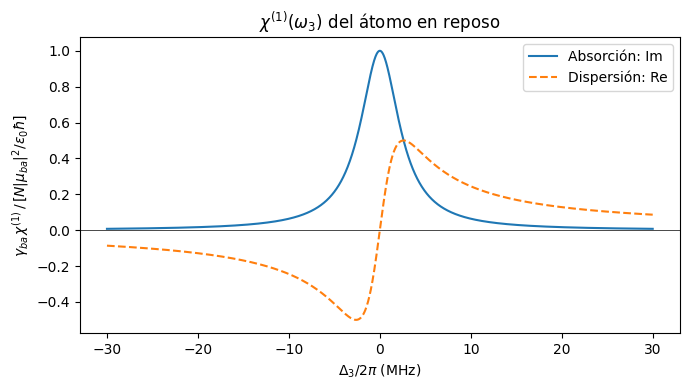

In [8]:
D3 = 2*np.pi*np.linspace(-30e6, 30e6, 2001)
x1 = g_ba*chi1(D3)/pref1

plt.figure(figsize=(7, 4))
plt.plot(D3/2/np.pi/1e6, x1.imag, label=r"Absorción: Im")
plt.plot(D3/2/np.pi/1e6, x1.real, "--", label=r"Dispersión: Re")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel(r"$\Delta_3/2\pi$ (MHz)")
plt.ylabel(r"$\gamma_{ba}\,\chi^{(1)}\,/\,[N|\mu_{ba}|^2/\varepsilon_0\hbar]$")
plt.title(r"$\chi^{(1)}(\omega_3)$ del átomo en reposo ")
plt.legend(); plt.tight_layout(); plt.savefig("chi1_natural.pdf")

## 7. Cortes: lo que verías barriendo un solo láser

* **(a)** Barres el 822 con el 794 fijo en resonancia ($\delta_2 = 0$). Entonces $\Delta_3 = \Delta_2$ y se mueven dos denominadores a la vez: la línea es el producto de dos lorentzianas.
* **(b)** Barres el 794 con el 822 fijo en la resonancia de dos fotones ($\Delta_2 = 0$). Solo cambia $\Delta_3 = -\delta_2$: la línea es una lorentziana de ancho $\gamma_{ba}$.

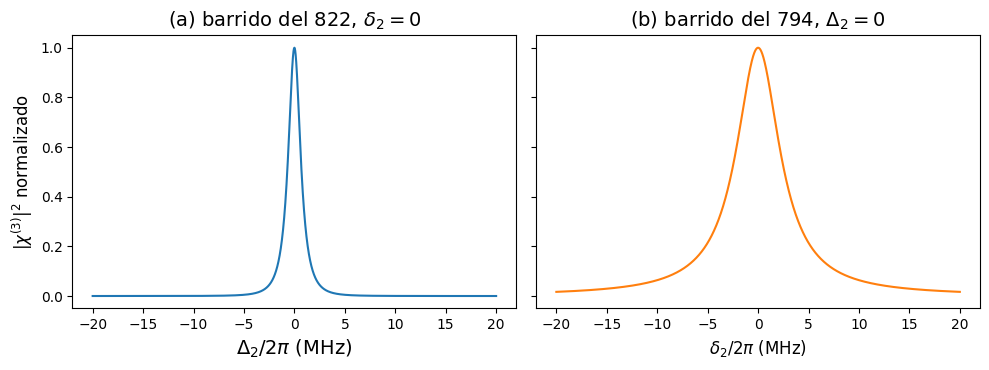

In [9]:
f = np.linspace(-20e6, 20e6, 20001)
Sa = np.abs(chi3(2*np.pi*f, 0.0))**2;  Sa /= Sa.max()
Sb = np.abs(chi3(0.0, 2*np.pi*f))**2;  Sb /= Sb.max()

fig, (axa, axb) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axa.plot(f/1e6, Sa); axa.set_xlabel(r"$\Delta_2/2\pi$ (MHz)", fontsize =14)
axa.set_title(r"(a) barrido del 822, $\delta_2=0$", fontsize=14)
axb.plot(f/1e6, Sb, color="C1")
axb.set_xlabel(r"$\delta_2/2\pi$ (MHz)", fontsize=12)
axb.set_title(r"(b) barrido del 794, $\Delta_2=0$", fontsize=14)
axa.set_ylabel(r"$|\chi^{(3)}|^2$ normalizado", fontsize=12)
plt.tight_layout()
plt.savefig("chi3_squared.pdf")

## 8. Mapa de $|\chi^{(3)}|^2$ en el plano de las dos perillas

Por (2.54) deben aparecer dos líneas de resonancia:

* **Vertical**, $\Delta_2 = 0$: resonancia de dos fotones $6S\to 8S$, con ancho $\gamma_{ca}$.
* **Diagonal**, $\Delta_3 = 0 \Rightarrow \delta_2 = \Delta_2$: el campo generado cae en resonancia con la D2, con ancho $\gamma_{ba}$.

El máximo está donde se cruzan: ambos láseres en resonancia a la vez.

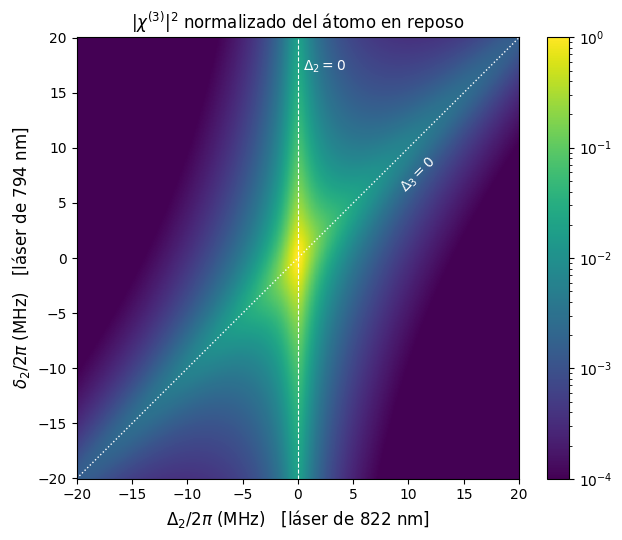

In [10]:
f = np.linspace(-20e6, 20e6, 801)
D2g, d2g = np.meshgrid(2*np.pi*f, 2*np.pi*f)
S = np.abs(chi3(D2g, d2g))**2
S /= S.max()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.pcolormesh(f/1e6, f/1e6, S, norm=LogNorm(vmin=1e-4, vmax=1), shading="auto", cmap="viridis")
ax.axvline(0, color="w", ls="--", lw=0.8)
ax.plot(f/1e6, f/1e6, "w:", lw=1)
ax.text(0.5, 17, r"$\Delta_2=0$", color="w", fontsize = 10)
ax.text(9, 6, r"$\Delta_3=0$", color="w", rotation=45, fontsize = 10)
ax.set_xlabel(r"$\Delta_2/2\pi$ (MHz)   [láser de 822 nm]", fontsize = 12)
ax.set_ylabel(r"$\delta_2/2\pi$ (MHz)   [láser de 794 nm]", fontsize = 12)
ax.set_title(r"$|\chi^{(3)}|^2$ normalizado del átomo en reposo", fontsize = 12)
cb = fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig("map_chi3_squared.png")

#9. Forma de la señal para la celda ópticamente gruesa:

Para la intensidad medida en el caso de la celda ópticamente gruesa ($\kappa L  \gg 1$) se tiene que :

$|\tilde{E}_3(L)|^2 \approx
  \dfrac{|\mu_{cb}|^4\,|\tilde{E}_1|^4\,|\tilde{E}_2|^2}
  {\hbar^4\,\bigl(\Delta_1^2+\gamma_{ba}^2\bigr)\bigl(\Delta_2^2+\gamma_{ca}^2\bigr)}$


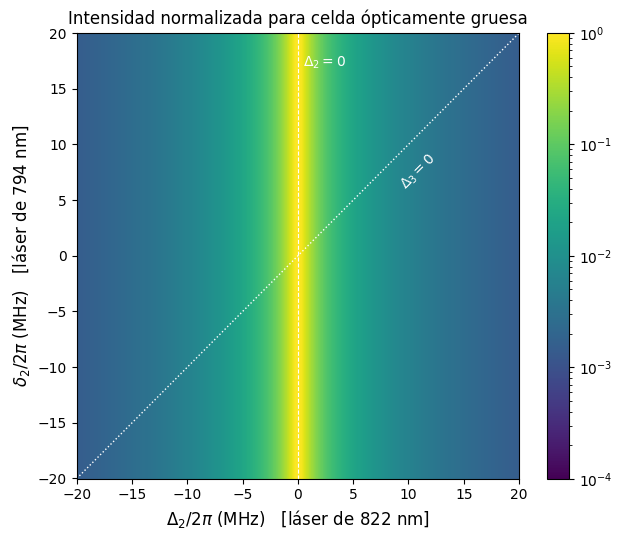

In [20]:
from matplotlib.colors import LogNorm

f = np.linspace(-20e6, 20e6, 801)
D2g, d2g = np.meshgrid(2*np.pi*f, 2*np.pi*f)

def thick_cell(D2, d2):
    D1, _ = desintonias(D2, d2)      # Δ1 depende solo de ω1, es decir, de Δ2
    first  = D1**2 + g_ba**2         # resonancia de un fotón del bombeo
    second = D2**2 + g_ca**2         # resonancia de dos fotones: ancho γ_ca
    return 1/(first*second)

I_thick = thick_cell(D2g, d2g)
I_thick = I_thick / I_thick.max()    # normalizar al máximo

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.pcolormesh(f/1e6, f/1e6, I_thick, norm=LogNorm(vmin=1e-4, vmax=1),
                   shading="auto", cmap="viridis")
ax.axvline(0, color="w", ls="--", lw=0.8)
ax.plot(f/1e6, f/1e6, "w:", lw=1)
ax.text(0.5, 17, r"$\Delta_2=0$", color="w", fontsize = 10)
ax.text(9, 6, r"$\Delta_3=0$", color="w", rotation=45, fontsize = 10)
ax.set_xlabel(r"$\Delta_2/2\pi$ (MHz)   [láser de 822 nm]", fontsize=12)
ax.set_ylabel(r"$\delta_2/2\pi$ (MHz)   [láser de 794 nm]", fontsize=12)
ax.set_title("Intensidad normalizada para celda ópticamente gruesa", fontsize=12)
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig("thick_cell.png", dpi=200)